In [1]:
## 1. Librerías

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
# Solo si se usa google colab ---
#from google.colab import drive

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression, Ridge

# Solo si se usa google colab ---
#drive.mount('/content/drive')

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [3]:
## 2. Carga de datos

In [4]:
#solicitudes_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_train.csv")
#comportamiento = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/comportamiento_bancario.csv")
#solicitudes_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_test.csv")

#Configurar ruta, lo veniamos usando con colab
solicitudes_train = pd.read_csv("solicitudes_train.csv")
comportamiento = pd.read_csv("comportamiento_bancario.csv")
solicitudes_test = pd.read_csv("solicitudes_test.csv")


In [5]:
## 3. Features de comportamiento bancario

In [6]:
solicitudes_completas = pd.concat([solicitudes_train, solicitudes_test])

historial_cruzado = comportamiento.merge(
    solicitudes_completas[["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud"]],
    on="ID_Usuario"
)

historial_cruzado["Fecha_Solicitud"] = pd.to_datetime(historial_cruzado["Fecha_Solicitud"])
historial_cruzado["Mes_Referencia"] = pd.to_datetime(historial_cruzado["Mes_Referencia"])

historial_valido = historial_cruzado[historial_cruzado["Mes_Referencia"] < historial_cruzado["Fecha_Solicitud"]]
historial_valido = historial_valido.sort_values(["ID_Solicitud", "Mes_Referencia"])

historial_valido["atraso"] = (historial_valido["Dias_Atraso_Otras_Deudas"] > 0).astype(int)
g = historial_valido.groupby("ID_Solicitud")

In [7]:
metricas_bancarias = g.agg(
    Saldo_Promedio=("Saldo_Promedio_Mensual", "mean"),
    Saldo_Std=("Saldo_Promedio_Mensual", "std"),
    Saldo_Ultimo=("Saldo_Promedio_Mensual", "last"),
    Atraso_Promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    Frac_Meses_Atraso=("atraso", "mean"),
    Atraso_Ultimo=("Dias_Atraso_Otras_Deudas", "last"),
)

for n in (3, 6):
    t = g.tail(n).groupby("ID_Solicitud").agg(**{
        f"Saldo_{n}m": ("Saldo_Promedio_Mensual", "mean"),
        f"Atraso_Prom_{n}m": ("Dias_Atraso_Otras_Deudas", "mean"),
        f"Atraso_Max_{n}m": ("Dias_Atraso_Otras_Deudas", "max"),
        f"Frac_Atraso_{n}m": ("atraso", "mean"),
    })
    metricas_bancarias = metricas_bancarias.join(t)

In [8]:
metricas_bancarias["Saldo_CV"] = metricas_bancarias["Saldo_Std"] / metricas_bancarias["Saldo_Promedio"].replace(0, np.nan)

metricas_bancarias["Aceleracion_Atraso"] = metricas_bancarias["Atraso_Prom_3m"] / metricas_bancarias["Atraso_Promedio"].replace(0, 1)

metricas_bancarias["Tendencia_Saldo"] = metricas_bancarias["Saldo_3m"] / metricas_bancarias["Saldo_6m"].replace(0, np.nan)
metricas_bancarias["Tendencia_Atraso"] = metricas_bancarias["Atraso_Prom_3m"] - metricas_bancarias["Atraso_Prom_6m"]

In [9]:
def racha_sin_atraso(sub_df):
    atrasos = sub_df["Dias_Atraso_Otras_Deudas"].values[::-1]
    racha = 0
    for a in atrasos:
        if a == 0:
            racha += 1
        else:
            break
    return racha

racha_df = g.apply(racha_sin_atraso).rename("Racha_Sin_Atraso").reset_index()
metricas_bancarias = metricas_bancarias.reset_index().merge(racha_df, on="ID_Solicitud")

In [10]:
## 4. Dataset final de train y test

In [11]:
#solicitudes_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_train.csv")
#solicitudes_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TP_ML2026/solicitudes_test.csv")

# Configurar rutas
solicitudes_train = pd.read_csv("solicitudes_train.csv")
solicitudes_test = pd.read_csv("solicitudes_test.csv")

solicitudes_train = solicitudes_train.merge(metricas_bancarias, on="ID_Solicitud", how="left")
solicitudes_test = solicitudes_test.merge(metricas_bancarias, on="ID_Solicitud", how="left")

for df in (solicitudes_train, solicitudes_test):
    df["Monto_sobre_Ingreso"] = df["Monto_Solicitado"] / df["Ingreso_Mensual"]
    df["Monto_sobre_Saldo"] = df["Monto_Solicitado"] / df["Saldo_Promedio"].replace(0, np.nan)

solicitudes_train = pd.get_dummies(solicitudes_train, columns=["Motivo_Prestamo"], drop_first=True)
solicitudes_test = pd.get_dummies(solicitudes_test, columns=["Motivo_Prestamo"], drop_first=True)

print("Dimensiones Train:", solicitudes_train.shape)
print("Dimensiones Test:", solicitudes_test.shape)

Dimensiones Train: (32416, 34)
Dimensiones Test: (3061, 33)


In [12]:
## 5. Features, target y split

In [13]:
columnas_a_borrar = ["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud", "Estado_Final"]
cols_monto = ["Monto_Solicitado", "Monto_sobre_Ingreso", "Monto_sobre_Saldo"]
X = solicitudes_train.drop(columns=columnas_a_borrar + cols_monto)
y = solicitudes_train["Estado_Final"]

In [14]:
fechas = pd.to_datetime(solicitudes_train["Fecha_Solicitud"])
corte = pd.Timestamp("2025-10-01")

idx_tr = np.where(fechas < corte)[0]
idx_val = np.where(fechas >= corte)[0]

usuarios_tr = set(solicitudes_train.iloc[idx_tr]["ID_Usuario"])
mask = ~solicitudes_train.iloc[idx_val]["ID_Usuario"].isin(usuarios_tr).values
idx_val = idx_val[mask]

X_train, X_val = X.iloc[idx_tr], X.iloc[idx_val]
y_train, y_val = y.iloc[idx_tr], y.iloc[idx_val]

In [15]:
## 6. Entrenamiento del modelo

In [16]:
#modelo = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
#modelo.fit(X_train, y_train)
#modelo = HistGradientBoostingClassifier(
#   learning_rate=0.05, max_iter=300, max_depth=4,
#   l2_regularization=1.0, random_state=42
#)
#modelo = HistGradientBoostingClassifier(
#   learning_rate=0.05, max_iter=300, max_depth=8,
#   l2_regularization=1.0, random_state=42
#)
#logit = Pipeline([
 #   ("imp", SimpleImputer(strategy="median")),
 #   ("sc", StandardScaler()),
  #  ("lr", LogisticRegression(C=0.3, max_iter=2000)),
#])

#ensemble = VotingClassifier(
  #  estimators=[("hgb", modelo), ("logit", logit)],
 #   voting="soft", weights=[2, 1],
#)
#ensemble.fit(X_train.replace([np.inf, -np.inf], np.nan), y_train)

#probabilidades_val_hgb = modelo.predict_proba(X_val)[:, 1]
#probabilidades_val = ensemble.predict_proba(X_val.replace([np.inf, -np.inf], np.nan))[:, 1]

modelo = HistGradientBoostingClassifier(
   learning_rate=0.05, max_iter=300, max_depth=3,
   l2_regularization=1.0, random_state=42
)
modelo.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",300
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",3
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing value

In [17]:
## 7. Evaluación en validación

In [18]:
probabilidades_val = modelo.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, probabilidades_val)
print(f"Puntuación AUC (capacidad predictiva): {auc:.4f}")

Puntuación AUC (capacidad predictiva): 0.8582


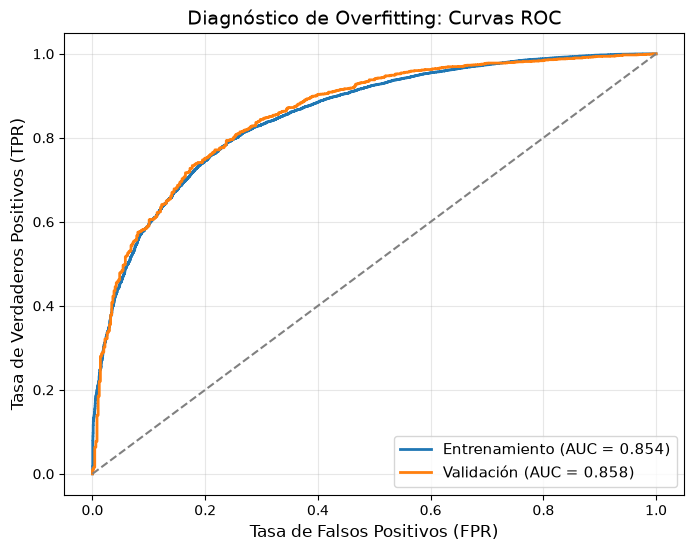

----------------------------------------
Diferencia de AUC: -0.005


In [19]:
probabilidades_train = modelo.predict_proba(X_train)[:, 1]
fpr_train, tpr_train, _ = roc_curve(y_train, probabilidades_train)
fpr_val, tpr_val, _ = roc_curve(y_val, probabilidades_val)

auc_train = roc_auc_score(y_train, probabilidades_train)
auc_val = roc_auc_score(y_val, probabilidades_val)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, color='#1f77b4', linewidth=2,
         label=f'Entrenamiento (AUC = {auc_train:.3f})')
plt.plot(fpr_val, tpr_val, color='#ff7f0e', linewidth=2,
         label=f'Validación (AUC = {auc_val:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

plt.title('Diagnóstico de Overfitting: Curvas ROC', fontsize=14)
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.show()

diferencia = auc_train - auc_val
print("-" * 40)
print(f"Diferencia de AUC: {diferencia:.3f}")

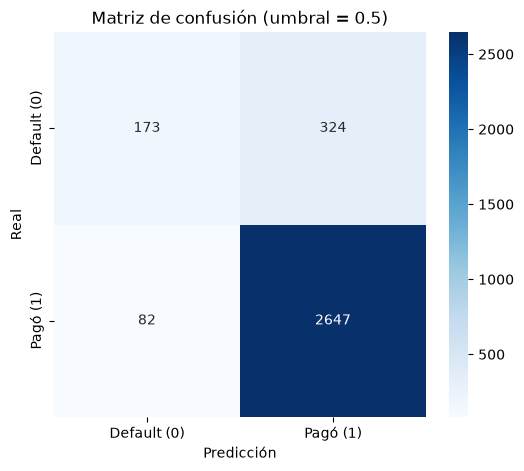

In [20]:
umbral = 0.5
y_pred_val = (probabilidades_val >= umbral).astype(int)

cm = confusion_matrix(y_val, y_pred_val)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Default (0)", "Pagó (1)"],
            yticklabels=["Default (0)", "Pagó (1)"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión (umbral = {umbral})")
plt.show()

In [21]:
## 8. Predicción sobre test y decisión de aprobación

In [22]:
columnas_a_borrar_test = ["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud"]
X_test = solicitudes_test.drop(columns=columnas_a_borrar_test + cols_monto)
X_test = X_test.reindex(columns=X.columns, fill_value=0)
modelo.fit(X, y)

probabilidades_test = modelo.predict_proba(X_test)[:, 1]
#probabilidades_test = ensemble.predict_proba(X_test)[:, 1]

In [23]:
resultados = solicitudes_test[["ID_Solicitud", "Monto_Solicitado", "Tasa_Interes"]].copy()
resultados["Prob_Paga"] = probabilidades_test
resultados["Prob_Default"] = 1 - resultados["Prob_Paga"]

resultados["Ganancia_Esperada"] = (
    resultados["Prob_Paga"] * (resultados["Monto_Solicitado"] * resultados["Tasa_Interes"])
    - resultados["Prob_Default"] * resultados["Monto_Solicitado"]
)
resultados["ROI_Esperado"] = resultados["Ganancia_Esperada"] / resultados["Monto_Solicitado"]

resultados = resultados.sort_values("ROI_Esperado", ascending=False)

In [24]:
PRESUPUESTO_MAX = 2000000

candidatos = resultados[resultados["ROI_Esperado"] > 0.02].copy()

candidatos["Monto_Acumulado"] = candidatos["Monto_Solicitado"].cumsum()

candidatos["Estado_Final"] = (candidatos["Monto_Acumulado"] <= PRESUPUESTO_MAX).astype(int)

resultados["Estado_Final"] = 0
resultados.loc[candidatos[candidatos["Estado_Final"] == 1].index, "Estado_Final"] = 1

In [25]:
## 9. Archivo de entrega

In [26]:
resultados = resultados.sort_values("ID_Solicitud")

entrega_final = resultados[["ID_Solicitud", "Estado_Final"]].rename(
    columns={"Estado_Final": "Decision_Aprobacion"}
)
entrega_final.to_csv("entrega_presta_match.csv", index=False)

In [27]:
capital_invertido = resultados[resultados['Estado_Final'] == 1]['Monto_Solicitado'].sum()
ganancia_proyectada = resultados[resultados['Estado_Final'] == 1]['Ganancia_Esperada'].sum()

print(f"Total de préstamos aprobados: {entrega_final['Decision_Aprobacion'].sum()}")
print(f"Capital total a invertir: ${capital_invertido:,.2f} USD")
print(f"Presupuesto sobrante: ${PRESUPUESTO_MAX - capital_invertido:,.2f} USD")
print(f"Ganancia Neta Proyectada: ${ganancia_proyectada:,.2f} USD")

Total de préstamos aprobados: 767
Capital total a invertir: $1,998,300.00 USD
Presupuesto sobrante: $1,700.00 USD
Ganancia Neta Proyectada: $493,050.50 USD


In [28]:
## 10. Decisión con ROI y presupuesto en validación

In [29]:
MONTO_MAX_TEST = 11000
fraccion_presupuesto = 2_000_000 / solicitudes_test["Monto_Solicitado"].sum()

In [30]:
val = solicitudes_train.iloc[idx_val][["Monto_Solicitado", "Tasa_Interes", "Estado_Final"]].copy()
val["p"] = probabilidades_val
val = val[val["Monto_Solicitado"] <= MONTO_MAX_TEST].copy()

val["roi"] = val["p"] * (1 + val["Tasa_Interes"]) - 1
val = val.sort_values("roi", ascending=False)

capital = val["Monto_Solicitado"].cumsum()
presupuesto_val = fraccion_presupuesto * val["Monto_Solicitado"].sum()

val["aprobado"] = ((val["roi"] > 0.02) & (capital <= presupuesto_val)).astype(int)

In [31]:
PRESUPUESTO_MAXIMO = 2000000

candidatos = val[val["aprobado"] == 1].copy()

aprobados = []
capital_acumulado = 0

for idx, prestamo in candidatos.iterrows():
    monto = prestamo["Monto_Solicitado"]

    if capital_acumulado + monto <= PRESUPUESTO_MAXIMO:
        aprobados.append(idx)
        capital_acumulado += monto

val["aprobado"] = 0
val.loc[aprobados, "aprobado"] = 1

val["ganancia_real"] = np.where(val["Estado_Final"] == 1,
                                val["Monto_Solicitado"] * val["Tasa_Interes"],
                                -val["Monto_Solicitado"])
ap = val[val["aprobado"] == 1]
print(f"Aprobados: {len(ap)} | capital: {ap['Monto_Solicitado'].sum():,.0f} USD")
print(f"Defaults entre aprobados: {(ap['Estado_Final'] == 0).mean():.1%}")
print(f"Ganancia real: {ap['ganancia_real'].sum():,.0f} USD")

Aprobados: 287 | capital: 1,999,700 USD
Defaults entre aprobados: 0.3%
Ganancia real: 534,052 USD


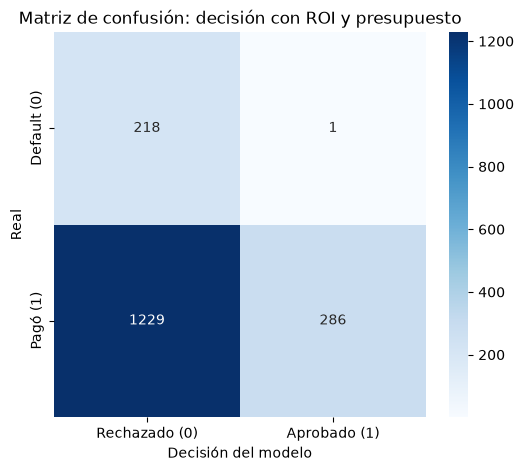

In [32]:
cm_dec = confusion_matrix(val["Estado_Final"], val["aprobado"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_dec, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rechazado (0)", "Aprobado (1)"],
            yticklabels=["Default (0)", "Pagó (1)"])
plt.xlabel("Decisión del modelo")
plt.ylabel("Real")
plt.title("Matriz de confusión: decisión con ROI y presupuesto")
plt.show()

In [33]:
usuarios_train = set(solicitudes_train["ID_Usuario"])
print("% de solicitudes de test cuyo usuario está en train:",
      solicitudes_test["ID_Usuario"].isin(usuarios_train).mean())
print("Fechas train:", solicitudes_train["Fecha_Solicitud"].min(), "→", solicitudes_train["Fecha_Solicitud"].max())
print("Fechas test: ", solicitudes_test["Fecha_Solicitud"].min(), "→", solicitudes_test["Fecha_Solicitud"].max())

% de solicitudes de test cuyo usuario está en train: 0.0
Fechas train: 2025-01 → 2025-12
Fechas test:  2026-01 → 2026-01


In [34]:
print(solicitudes_train.assign(mes=fechas.dt.to_period("M"))
      .groupby("mes")["Estado_Final"].agg(["mean", "count"]))

cols = ["Monto_Solicitado", "Tasa_Interes", "Ingreso_Mensual"]
print(solicitudes_train[cols].describe())
print(solicitudes_test[cols].describe())
print("p media validación:", probabilidades_val.mean(),
      "| p media test:", probabilidades_test.mean())

             mean  count
mes                     
2025-01  0.840183   2628
2025-02  0.841357   2742
2025-03  0.845902   2745
2025-04  0.829907   2675
2025-05  0.830866   2702
2025-06  0.843956   2730
2025-07  0.840901   2709
2025-08  0.840058   2751
2025-09  0.844592   2709
2025-10  0.836832   2715
2025-11  0.848317   2703
2025-12  0.842731   2607
       Monto_Solicitado  Tasa_Interes  Ingreso_Mensual
count      32416.000000  32416.000000     32416.000000
mean       14290.097483      0.259580      4214.475938
std        12995.295179      0.032333      2498.904569
min          500.000000      0.147600       353.000000
25%         5700.000000      0.237300      2481.000000
50%        10200.000000      0.258300      3621.000000
75%        18100.000000      0.280600      5276.000000
max        70000.000000      0.379900     22000.000000
       Monto_Solicitado  Tasa_Interes  Ingreso_Mensual
count       3061.000000   3061.000000      3061.000000
mean        2235.315256      0.258836      42

In [35]:
bins = pd.cut(solicitudes_train["Monto_Solicitado"], [0, 1000, 2000, 3000, 5000, 11000, 20000, 70000])
print(solicitudes_train.groupby(bins, observed=True)["Estado_Final"].agg(["mean", "count"]))
print("% de train con monto <= 11000:", (solicitudes_train["Monto_Solicitado"] <= 11000).mean())

                      mean  count
Monto_Solicitado                 
(0, 1000]         0.915152    165
(1000, 2000]      0.878547    881
(2000, 3000]      0.863055   1643
(3000, 5000]      0.882673   4040
(5000, 11000]     0.862361  10760
(11000, 20000]    0.828317   7974
(20000, 70000]    0.784122   6953
% de train con monto <= 11000: 0.5395175222112537


In [36]:
chicos = solicitudes_train.iloc[idx_val]["Monto_Solicitado"].values <= 3000
print("n:", chicos.sum(),
      "| tasa de pago real:", y_val.values[chicos].mean(),
      "| p media predicha:", probabilidades_val[chicos].mean())

n: 268 | tasa de pago real: 0.8805970149253731 | p media predicha: 0.8617249729224077


In [37]:
from sklearn.base import clone

modelos = {
    "HGB": lambda: clone(modelo),
    "RF": lambda: Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20,
                                      random_state=42, n_jobs=-1)),
    ]),
    "LogReg": lambda: Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000)),
    ]),
}

def metricas(p, va):
    v = solicitudes_train.iloc[va][["Monto_Solicitado", "Tasa_Interes", "Estado_Final"]].copy()
    v["p"] = p
    v = v[v["Monto_Solicitado"] <= 11000].copy()
    auc_v = roc_auc_score(v["Estado_Final"], v["p"])
    v["roi"] = v["p"] * (1 + v["Tasa_Interes"]) - 1
    v = v.sort_values("roi", ascending=False)
    cap = v["Monto_Solicitado"].cumsum()
    pres = fraccion_presupuesto * v["Monto_Solicitado"].sum()
    ap = v[(v["roi"] > 0.02) & (cap <= pres)]
    g = np.where(ap["Estado_Final"] == 1,
                 ap["Monto_Solicitado"] * ap["Tasa_Interes"],
                 -ap["Monto_Solicitado"])
    return {"AUC": auc_v, "aprobados": len(ap),
            "defaults": (ap["Estado_Final"] == 0).mean(),
            "ganancia_por_dolar": g.sum() / ap["Monto_Solicitado"].sum()}

fechas_tr = pd.to_datetime(solicitudes_train["Fecha_Solicitud"])
filas = []

for corte in ["2025-07-01", "2025-09-01", "2025-10-01"]:
    tr = np.where(fechas_tr < pd.Timestamp(corte))[0]
    va = np.where(fechas_tr >= pd.Timestamp(corte))[0]
    usuarios = set(solicitudes_train.iloc[tr]["ID_Usuario"])
    va = va[~solicitudes_train.iloc[va]["ID_Usuario"].isin(usuarios).values]

    probs = {}
    for nombre, crear in modelos.items():
        m = crear().fit(X.iloc[tr], y.iloc[tr])
        probs[nombre] = m.predict_proba(X.iloc[va])[:, 1]
    probs["HGB+RF"] = (probs["HGB"] + probs["RF"]) / 2

    for nombre, p in probs.items():
        filas.append({"corte": corte, "modelo": nombre, **metricas(p, va)})

res = pd.DataFrame(filas)
print(res.round(3).to_string(index=False))
print()
print(res.groupby("modelo")[["AUC", "defaults", "ganancia_por_dolar"]]
      .mean().round(3).sort_values("ganancia_por_dolar", ascending=False))

     corte modelo   AUC  aprobados  defaults  ganancia_por_dolar
2025-07-01    HGB 0.831       1292     0.022               0.239
2025-07-01     RF 0.828       1273     0.023               0.236
2025-07-01 LogReg 0.832       1277     0.021               0.233
2025-07-01 HGB+RF 0.830       1278     0.022               0.238
2025-09-01    HGB 0.853        690     0.013               0.250
2025-09-01     RF 0.851        676     0.012               0.251
2025-09-01 LogReg 0.851        683     0.012               0.245
2025-09-01 HGB+RF 0.853        680     0.010               0.253
2025-10-01    HGB 0.848        463     0.011               0.253
2025-10-01     RF 0.849        455     0.011               0.251
2025-10-01 LogReg 0.851        456     0.007               0.251
2025-10-01 HGB+RF 0.849        458     0.011               0.253

          AUC  defaults  ganancia_por_dolar
modelo                                     
HGB     0.844     0.015               0.248
HGB+RF  0.844     0.01

In [38]:
filas = []
for corte in ["2025-07-01", "2025-09-01", "2025-10-01"]:
    tr = np.where(fechas_tr < pd.Timestamp(corte))[0]
    va = np.where(fechas_tr >= pd.Timestamp(corte))[0]
    usuarios = set(solicitudes_train.iloc[tr]["ID_Usuario"])
    va = va[~solicitudes_train.iloc[va]["ID_Usuario"].isin(usuarios).values]

    for d in [3, 4, 6, 8]:
        m = clone(modelo).set_params(max_depth=d).fit(X.iloc[tr], y.iloc[tr])
        p_tr = m.predict_proba(X.iloc[tr])[:, 1]
        p_va = m.predict_proba(X.iloc[va])[:, 1]
        r = metricas(p_va, va)
        filas.append({"corte": corte, "max_depth": d, "AUC_val": r["AUC"],
                      "brecha": roc_auc_score(y.iloc[tr], p_tr) - roc_auc_score(y.iloc[va], p_va),
                      "defaults": r["defaults"], "ganancia_por_dolar": r["ganancia_por_dolar"]})

res_d = pd.DataFrame(filas)
print(res_d.round(3).to_string(index=False))
print()
print(res_d.groupby("max_depth")[["AUC_val", "brecha", "defaults", "ganancia_por_dolar"]].mean().round(3))

     corte  max_depth  AUC_val  brecha  defaults  ganancia_por_dolar
2025-07-01          3    0.831   0.022     0.022               0.239
2025-07-01          4    0.829   0.030     0.022               0.240
2025-07-01          6    0.828   0.052     0.022               0.239
2025-07-01          8    0.830   0.060     0.020               0.241
2025-09-01          3    0.853  -0.001     0.013               0.250
2025-09-01          4    0.852   0.007     0.013               0.250
2025-09-01          6    0.848   0.030     0.016               0.245
2025-09-01          8    0.850   0.025     0.012               0.253
2025-10-01          3    0.848  -0.005     0.011               0.253
2025-10-01          4    0.847   0.002     0.013               0.249
2025-10-01          6    0.849   0.016     0.009               0.253
2025-10-01          8    0.847   0.020     0.013               0.249

           AUC_val  brecha  defaults  ganancia_por_dolar
max_depth                                    